##   --↝ Bike Sharing Demand

    Importing Important Libraries.

In [224]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
%matplotlib inline
sns.set_style('darkgrid')

import datetime as dt, warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Let's refer to DataSet as our analysis.

In [ ]:
# day.csv contain actual data so we have to train and test the data.
bike_df = pd.read_csv('day.csv')
bike_df.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2018,1,0,1,0,1,1,2,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,02-01-2018,1,0,1,0,2,1,2,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,03-01-2018,1,0,1,0,3,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,04-01-2018,1,0,1,0,4,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,05-01-2018,1,0,1,0,5,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600


In [ ]:
 # The Shape determines the actual rows and columns.
 bike_df.shape

(730, 16)

In [ ]:
bike_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     730 non-null    int64  
 1   dteday      730 non-null    object 
 2   season      730 non-null    int64  
 3   yr          730 non-null    int64  
 4   mnth        730 non-null    int64  
 5   holiday     730 non-null    int64  
 6   weekday     730 non-null    int64  
 7   workingday  730 non-null    int64  
 8   weathersit  730 non-null    int64  
 9   temp        730 non-null    float64
 10  atemp       730 non-null    float64
 11  hum         730 non-null    float64
 12  windspeed   730 non-null    float64
 13  casual      730 non-null    int64  
 14  registered  730 non-null    int64  
 15  cnt         730 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.4+ KB


In [ ]:
bike_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000,730.000000
mean,365.500000,2.498630,0.500000,6.526027,0.028767,2.995890,0.690411,1.394521,20.319259,23.726322,62.765175,12.763620,849.249315,3658.757534,4508.006849
std,210.877136,1.110184,0.500343,3.450215,0.167266,2.000339,0.462641,0.544807,7.506729,8.150308,14.237589,5.195841,686.479875,1559.758728,1936.011647
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,2.424346,3.953480,0.000000,1.500244,2.000000,20.000000,22.000000
25%,183.250000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,13.811885,16.889713,52.000000,9.041650,316.250000,2502.250000,3169.750000
50%,365.500000,3.000000,0.500000,7.000000,0.000000,3.000000,1.000000,1.000000,20.465826,24.368225,62.625000,12.125325,717.000000,3664.500000,4548.500000
75%,547.750000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,26.880615,30.445775,72.989575,15.625589,1096.500000,4783.250000,5966.000000
max,730.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,35.328347,42.044800,97.250000,34.000021,3410.000000,6946.000000,8714.000000


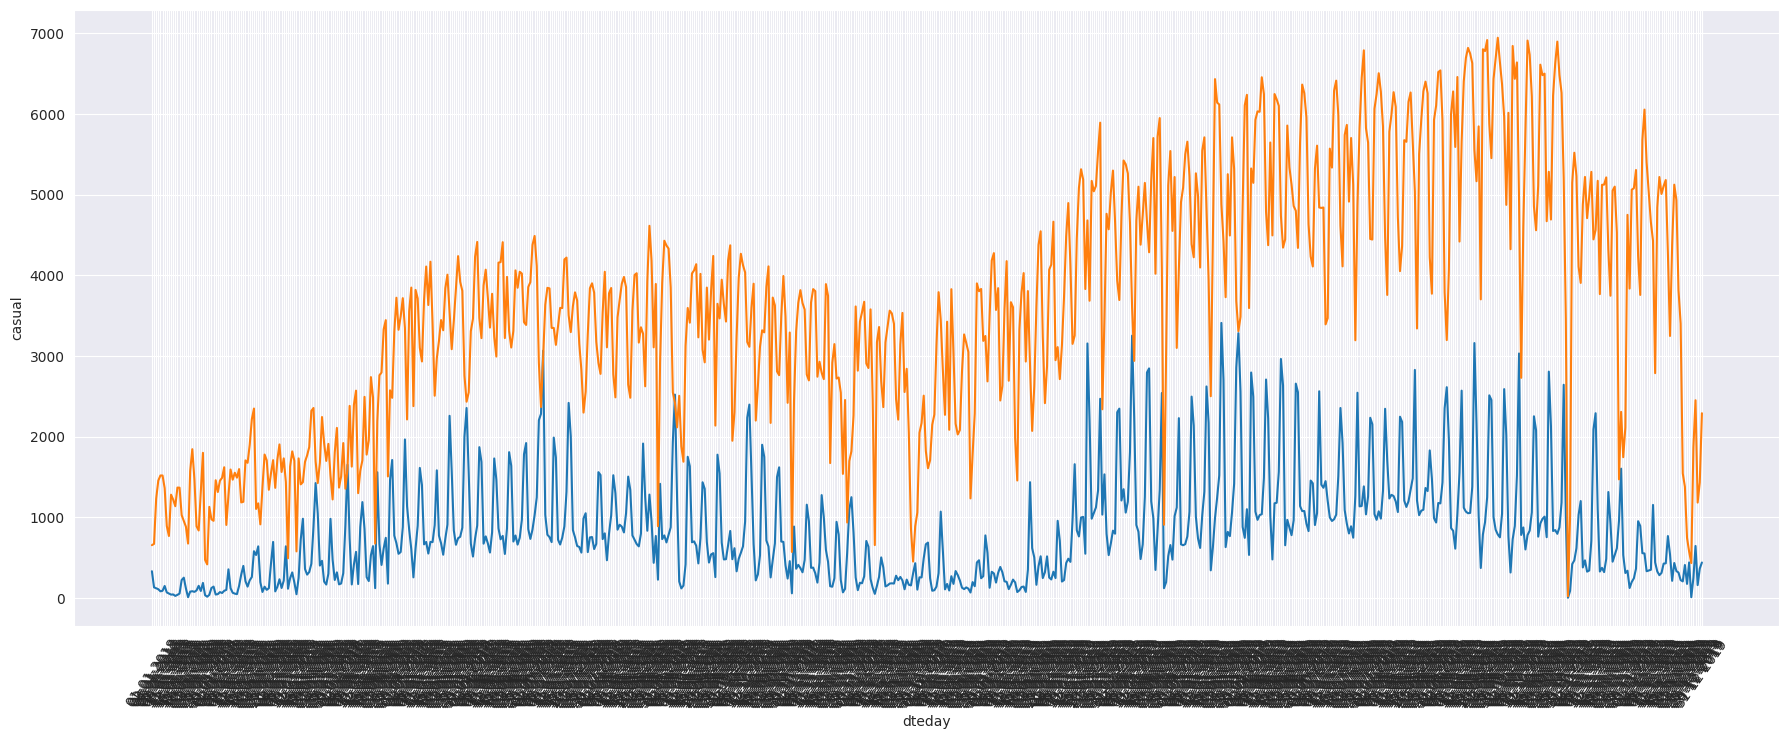

In [ ]:
plt.figure(figsize = (22,8))
sns.lineplot(x = bike_df["dteday"], y = bike_df["casual"])
sns.lineplot(x = bike_df["dteday"], y = bike_df["registered"])
plt.xticks(rotation = 55)
plt.show()

In [ ]:
bike_df[['casual', 'registered']].corr()

,casual,registered
casual,1.000000,0.394137
registered,0.394137,1.000000


In [ ]:
bike_df[['temp', 'atemp']].corr()

,temp,atemp
temp,1.000000,0.991696
atemp,0.991696,1.000000


I evaluated all aspects and concluded that each column is useful, however I assume that instant, temp, casual, and registered.
So, I dropped:
    Instant - Works as a serial number or index number.

    Temp - A temp and Atemp coincide, hence I opted to keep 1.
    Casual and Registered are equivalent to the overall count 'cnt', therefore I decided to drop them both.

    One key difference between Casual and Registered is that keeping the columns allows for overfitting of the data. Since the sum of Casual and Registered equals cnt, the model can read the value as Casual and Registered.


In [ ]:
bike_df.drop(['instant', 'temp', 'casual', 'registered'], axis = 1, inplace = True)

In [ ]:
bike_df['dteday'] = pd.to_datetime(bike_df['dteday'], format = '%d-%m-%Y')
bike_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,atemp,hum,windspeed,cnt
0,2018-01-01,1,0,1,0,1,1,2,18.18125,80.5833,10.749882,985
1,2018-01-02,1,0,1,0,2,1,2,17.68695,69.6087,16.652113,801
2,2018-01-03,1,0,1,0,3,1,1,9.47025,43.7273,16.636703,1349
3,2018-01-04,1,0,1,0,4,1,1,10.60610,59.0435,10.739832,1562
4,2018-01-05,1,0,1,0,5,1,1,11.46350,43.6957,12.522300,1600


For EDA and visualization, we need to decode the columns and turn the numbers to text.


In [ ]:
bike_df['season'].replace(to_replace = [1, 2, 3, 4], value = ['spring', 'summer', 'fall', 'winter'], inplace = True)
bike_df['holiday'].replace(to_replace = [0, 1], value = ['No', 'Yes'], inplace = True)
bike_df['workingday'].replace(to_replace = [0, 1], value = ['No', 'Yes'], inplace = True)
bike_df['weathersit'].replace(to_replace = [1, 2, 3, 4], value = ['Clear', 'Mist', 'Light', 'Heavy'], inplace = True)
bike_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,atemp,hum,windspeed,cnt
0,2018-01-01,spring,0,1,No,1,Yes,Mist,18.18125,80.5833,10.749882,985
1,2018-01-02,spring,0,1,No,2,Yes,Mist,17.68695,69.6087,16.652113,801
2,2018-01-03,spring,0,1,No,3,Yes,Clear,9.47025,43.7273,16.636703,1349
3,2018-01-04,spring,0,1,No,4,Yes,Clear,10.60610,59.0435,10.739832,1562
4,2018-01-05,spring,0,1,No,5,Yes,Clear,11.46350,43.6957,12.522300,1600


In [ ]:
bike_df['weekday'] = bike_df['dteday'].dt.day_name()
bike_df['mnth'] = bike_df['dteday'].dt.month_name()
bike_df['yr'] = bike_df['dteday'].dt.year
bike_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,atemp,hum,windspeed,cnt
0,2018-01-01,spring,2018,January,No,Monday,Yes,Mist,18.18125,80.5833,10.749882,985
1,2018-01-02,spring,2018,January,No,Tuesday,Yes,Mist,17.68695,69.6087,16.652113,801
2,2018-01-03,spring,2018,January,No,Wednesday,Yes,Clear,9.47025,43.7273,16.636703,1349
3,2018-01-04,spring,2018,January,No,Thursday,Yes,Clear,10.60610,59.0435,10.739832,1562
4,2018-01-05,spring,2018,January,No,Friday,Yes,Clear,11.46350,43.6957,12.522300,1600


In [ ]:
bike_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      730 non-null    datetime64[ns]
 1   season      730 non-null    object        
 2   yr          730 non-null    int32         
 3   mnth        730 non-null    object        
 4   holiday     730 non-null    object        
 5   weekday     730 non-null    object        
 6   workingday  730 non-null    object        
 7   weathersit  730 non-null    object        
 8   atemp       730 non-null    float64       
 9   hum         730 non-null    float64       
 10  windspeed   730 non-null    float64       
 11  cnt         730 non-null    int64         
dtypes: datetime64[ns](1), float64(3), int32(1), int64(1), object(6)
memory usage: 65.7+ KB


In [ ]:
bike_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,atemp,hum,windspeed,cnt
0,2018-01-01,spring,2018,January,No,Monday,Yes,Mist,18.18125,80.5833,10.749882,985
1,2018-01-02,spring,2018,January,No,Tuesday,Yes,Mist,17.68695,69.6087,16.652113,801
2,2018-01-03,spring,2018,January,No,Wednesday,Yes,Clear,9.47025,43.7273,16.636703,1349
3,2018-01-04,spring,2018,January,No,Thursday,Yes,Clear,10.60610,59.0435,10.739832,1562
4,2018-01-05,spring,2018,January,No,Friday,Yes,Clear,11.46350,43.6957,12.522300,1600


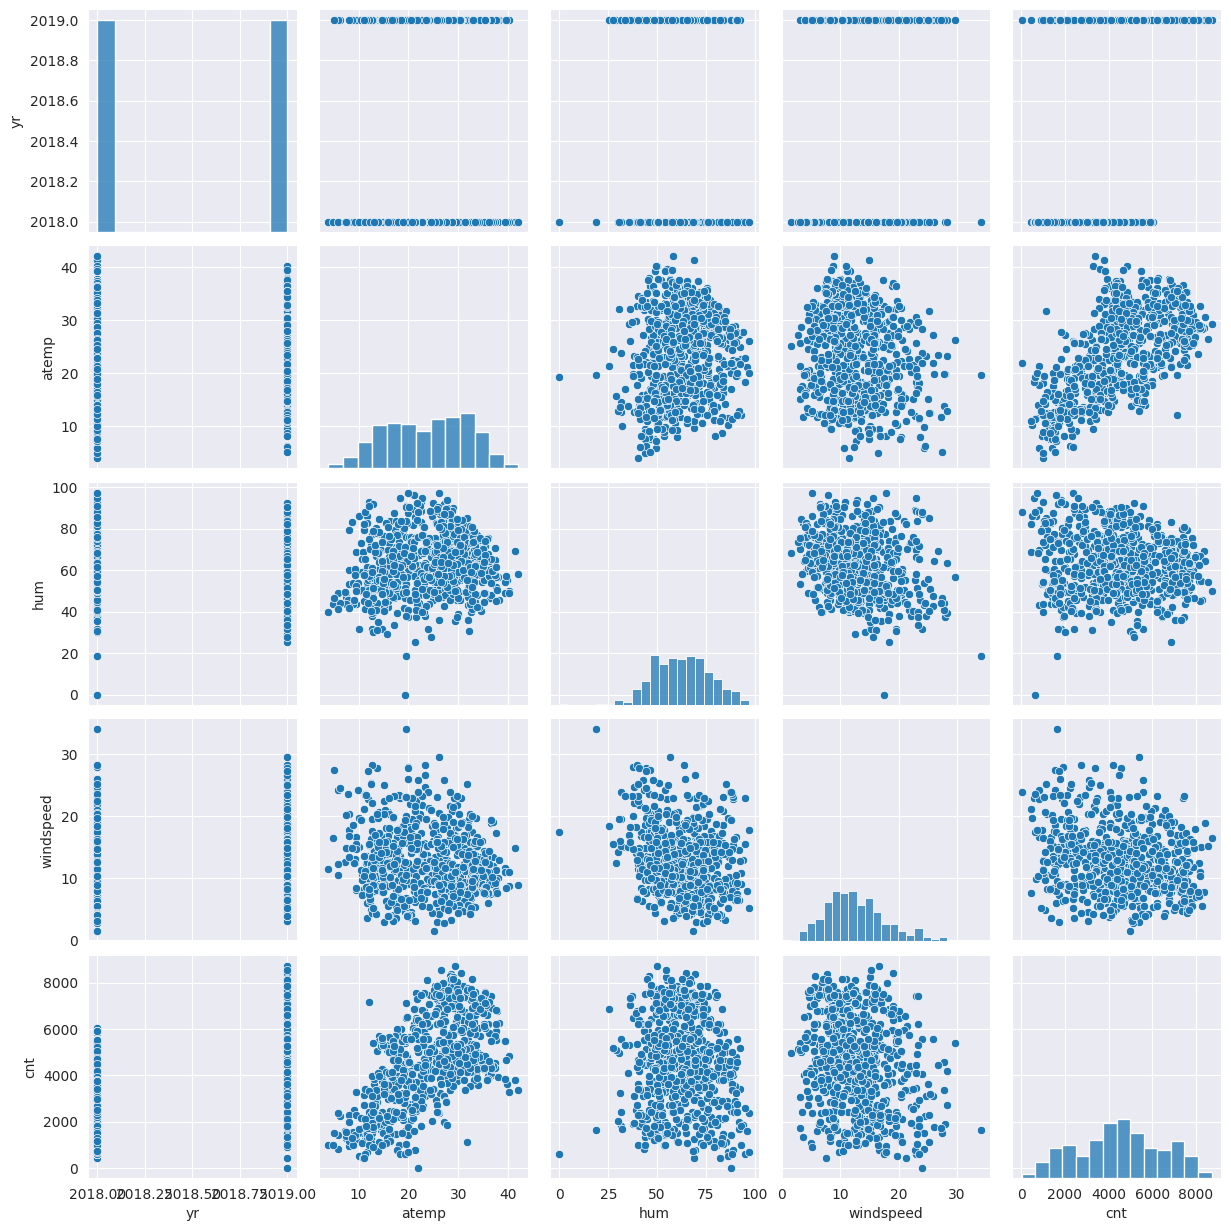

In [ ]:
sns.pairplot(bike_df)
plt.show()

  Let's look at aspects like Season, Holiday, and Month with CNT.

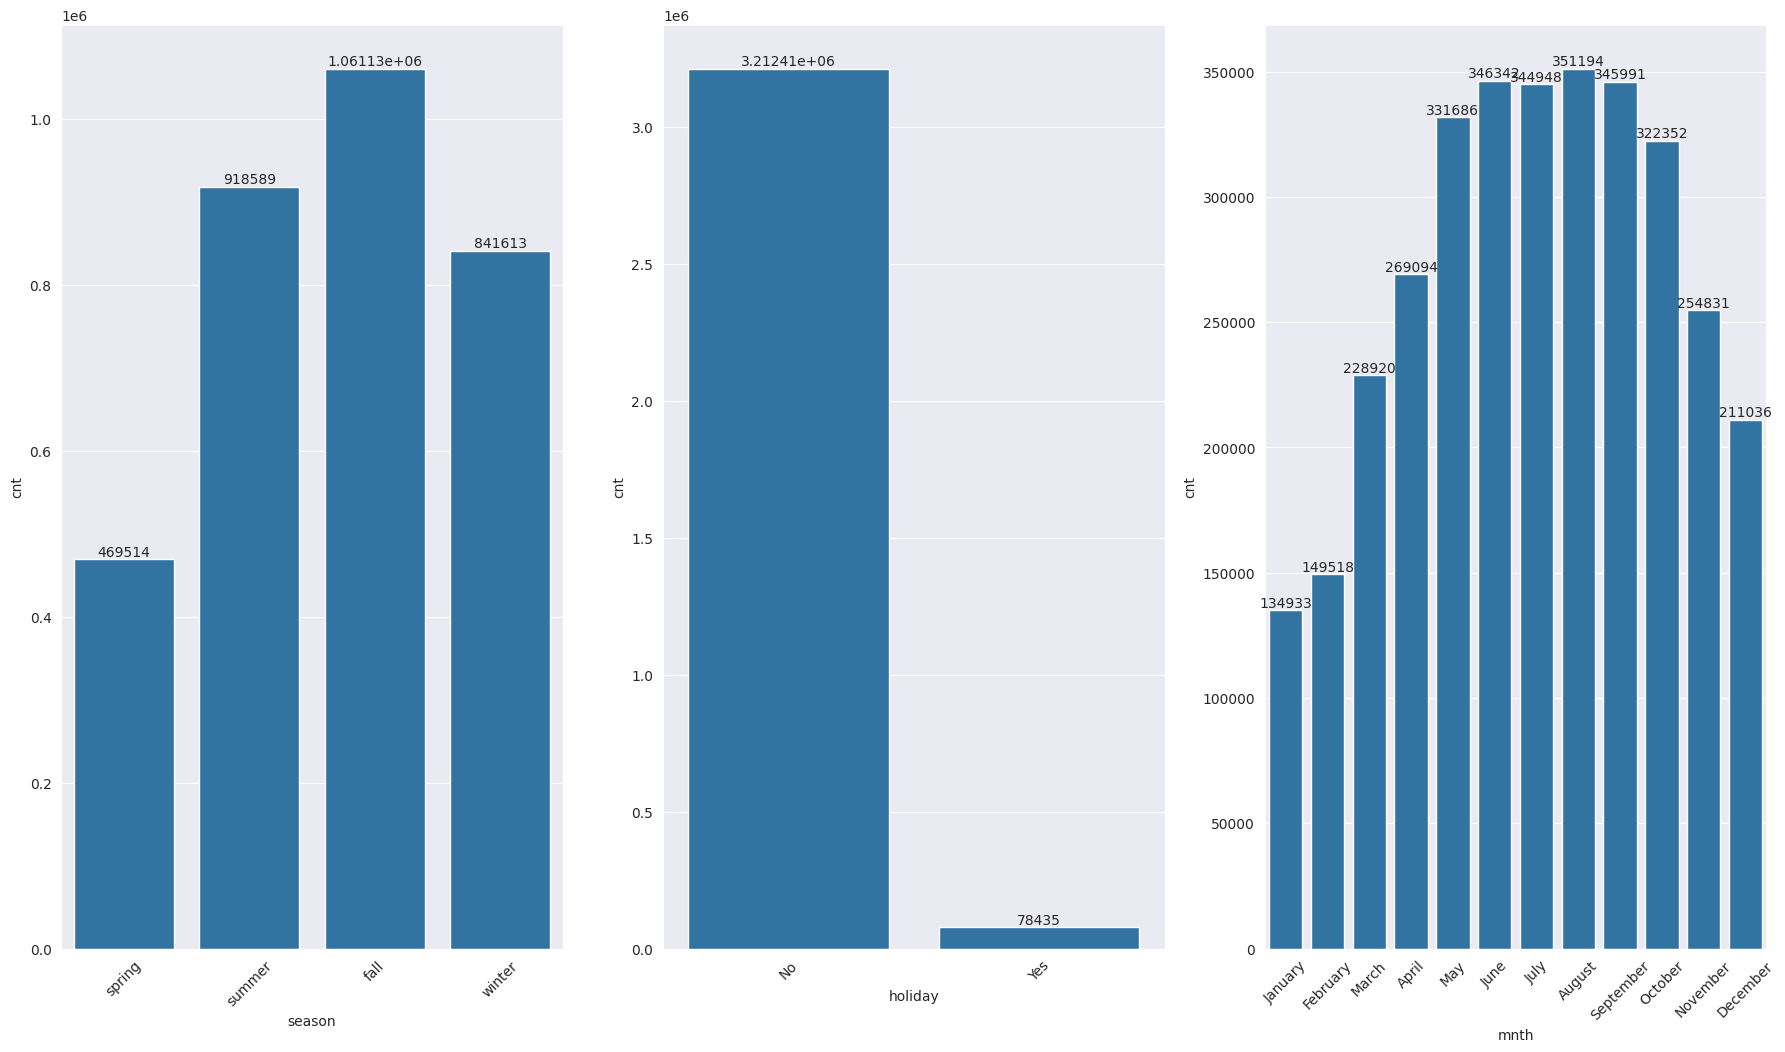

In [ ]:
plt.figure(figsize = (22,12))
plt.subplot(1,3,1)
plt.xticks(rotation = 45)
ax = sns.barplot(bike_df, y = "cnt", x = "season", estimator = "sum", errorbar=None)
ax.bar_label(ax.containers[0], fontsize = 10);
plt.subplot(1,3,2)
plt.xticks(rotation = 45)
ax = sns.barplot(bike_df, y = "cnt", x = "holiday", estimator = "sum", errorbar=None)
ax.bar_label(ax.containers[0], fontsize = 10);
plt.subplot(1,3,3)
plt.xticks(rotation = 45)
ax = sns.barplot(bike_df, y = "cnt", x = "mnth", estimator = "sum", errorbar=None)
ax.bar_label(ax.containers[0], fontsize = 10);
plt.show()

The features provide insights into seasonal trends, such as increased bike usage throughout the fall.
    The demand for bikes increases in months such as June, July, August, and September.


Let's find out some features like weekday, workingday, and weathersit with cnt.


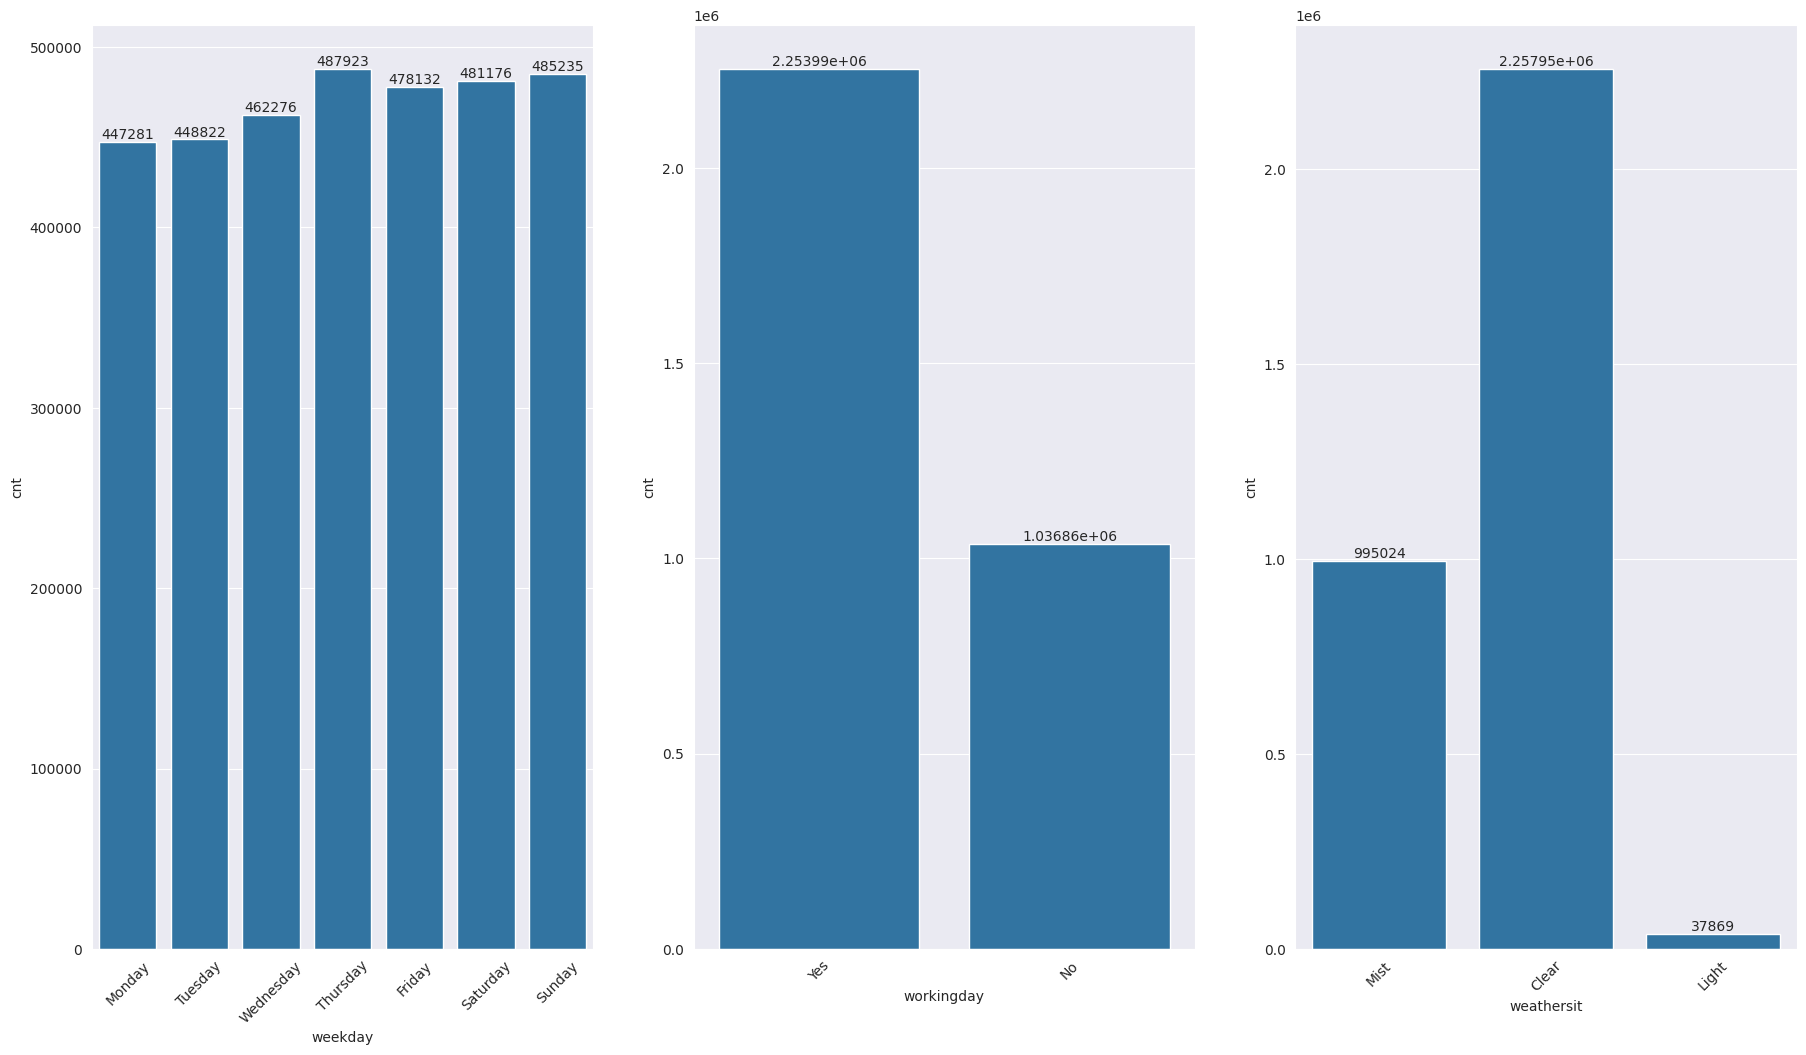

In [ ]:
plt.figure(figsize = (22,12))
plt.subplot(1,3,1)
plt.xticks(rotation = 45)
ax = sns.barplot(bike_df, y = "cnt", x = "weekday", estimator = "sum", errorbar=None)
ax.bar_label(ax.containers[0], fontsize = 10);
plt.subplot(1,3,2)
plt.xticks(rotation = 45)
ax = sns.barplot(bike_df, y = "cnt", x = "workingday", estimator = "sum", errorbar=None)
ax.bar_label(ax.containers[0], fontsize = 10);
plt.subplot(1,3,3)
plt.xticks(rotation = 45)
ax = sns.barplot(bike_df, y = "cnt", x = "weathersit", estimator = "sum", errorbar=None)
ax.bar_label(ax.containers[0], fontsize = 10);
plt.show()

   The features suggest that weekdays are equally relevant.
        It is best to buy a bike for hire during the clear season.

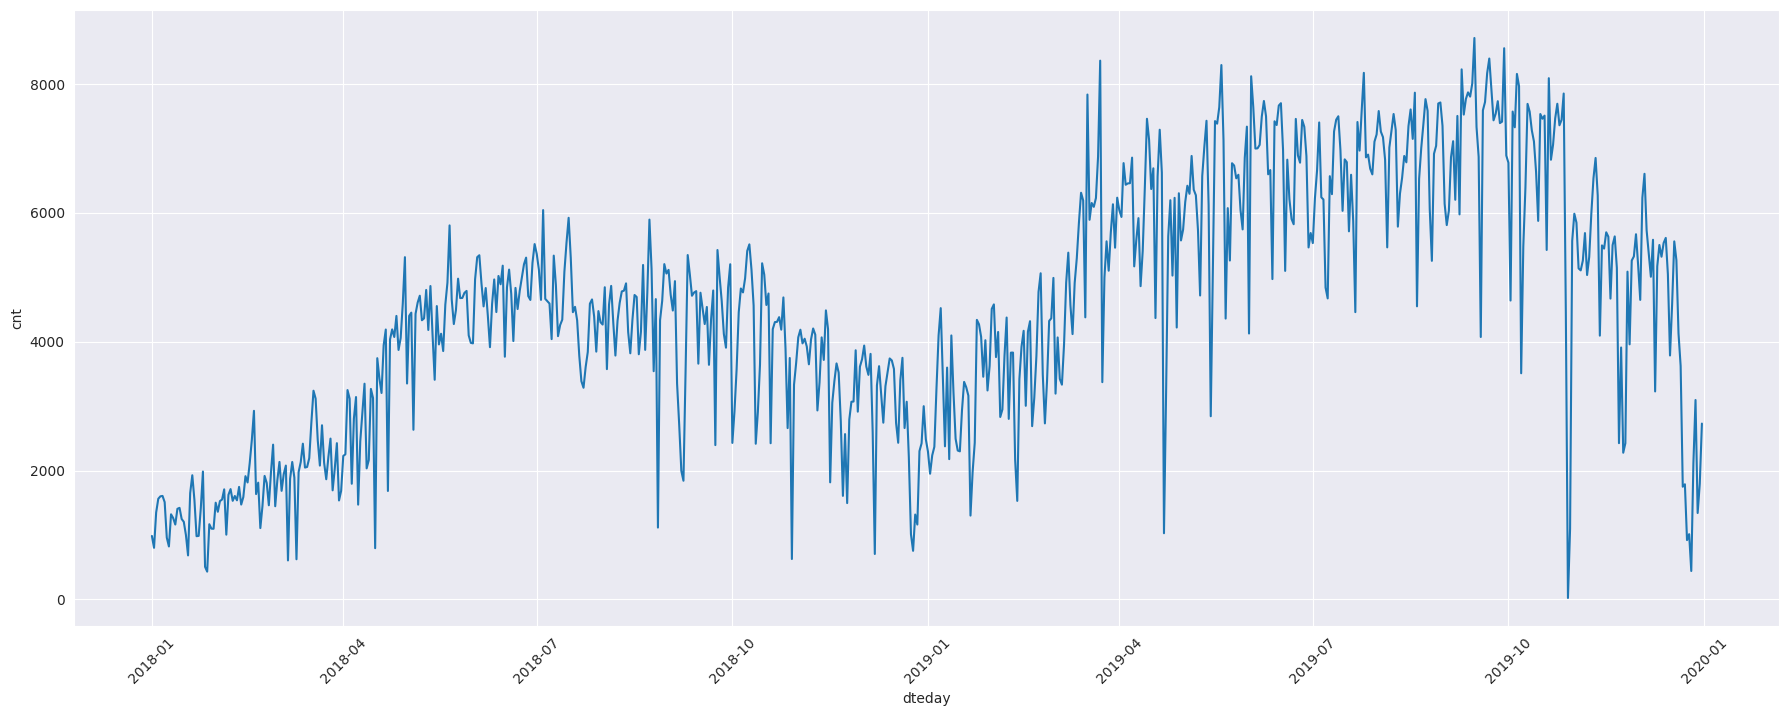

In [ ]:
plt.figure(figsize = (22,8))
sns.lineplot(x = bike_df["dteday"], y = bike_df["cnt"])
plt.xticks(rotation = 45)
plt.show()

  There is a rise in demand for rental bikes from 2018 to 2019, which could lead to increased buzz.
    and equal patterns throughout the middle of the year, from June to September.


In [ ]:
bike_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,atemp,hum,windspeed,cnt
0,2018-01-01,spring,2018,January,No,Monday,Yes,Mist,18.18125,80.5833,10.749882,985
1,2018-01-02,spring,2018,January,No,Tuesday,Yes,Mist,17.68695,69.6087,16.652113,801
2,2018-01-03,spring,2018,January,No,Wednesday,Yes,Clear,9.47025,43.7273,16.636703,1349
3,2018-01-04,spring,2018,January,No,Thursday,Yes,Clear,10.60610,59.0435,10.739832,1562
4,2018-01-05,spring,2018,January,No,Friday,Yes,Clear,11.46350,43.6957,12.522300,1600


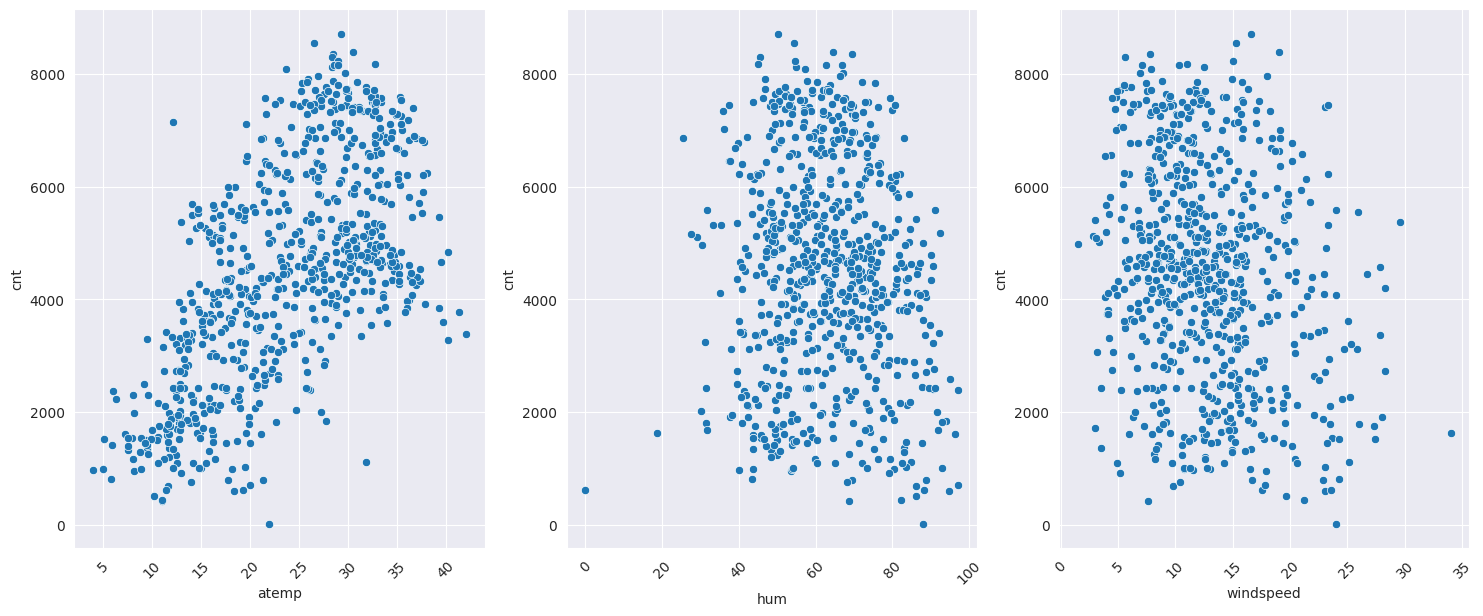

In [ ]:
plt.figure(figsize = (18,7))
plt.subplot(1,3,1)
plt.xticks(rotation = 45)
sns.scatterplot(x = bike_df['atemp'], y = bike_df['cnt'])
ax.bar_label(ax.containers[0], fontsize = 10);
plt.subplot(1,3,2)
plt.xticks(rotation = 45)
sns.scatterplot(x = bike_df['hum'], y = bike_df['cnt'])
ax.bar_label(ax.containers[0], fontsize = 10);
plt.subplot(1,3,3)
plt.xticks(rotation = 45)
sns.scatterplot(x = bike_df['windspeed'], y = bike_df['cnt'])
ax.bar_label(ax.containers[0], fontsize = 10);
plt.show()

> Now Creating Dummies and providing the numerical values for model

In [ ]:
for col in bike_df.iloc[:,1:8] :
    print(round(bike_df[col].value_counts(normalize=True) * 100, 2))

season
fall      25.75
summer    25.21
spring    24.66
winter    24.38
Name: proportion, dtype: float64
yr
2018    50.0
2019    50.0
Name: proportion, dtype: float64
mnth
January      8.49
March        8.49
May          8.49
July         8.49
August       8.49
October      8.49
December     8.49
April        8.22
June         8.22
September    8.22
November     8.22
February     7.67
Name: proportion, dtype: float64
holiday
No     97.12
Yes     2.88
Name: proportion, dtype: float64
weekday
Monday       14.38
Tuesday      14.38
Wednesday    14.25
Thursday     14.25
Friday       14.25
Saturday     14.25
Sunday       14.25
Name: proportion, dtype: float64
workingday
Yes    69.04
No     30.96
Name: proportion, dtype: float64
weathersit
Clear    63.42
Mist     33.70
Light     2.88
Name: proportion, dtype: float64


In [ ]:
df = pd.get_dummies(bike_df.iloc[:,1:8], drop_first=True, dtype=int)

In [ ]:
df.head()

,yr,season_spring,season_summer,season_winter,mnth_August,mnth_December,mnth_February,mnth_January,mnth_July,mnth_June,...,holiday_Yes,weekday_Monday,weekday_Saturday,weekday_Sunday,weekday_Thursday,weekday_Tuesday,weekday_Wednesday,workingday_Yes,weathersit_Light,weathersit_Mist
0,2018,1,0,0,0,0,0,1,0,0,...,0,1,0,0,0,0,0,1,0,1
1,2018,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,1
2,2018,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,1,1,0,0
3,2018,1,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,1,0,0
4,2018,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0


<Axes: >

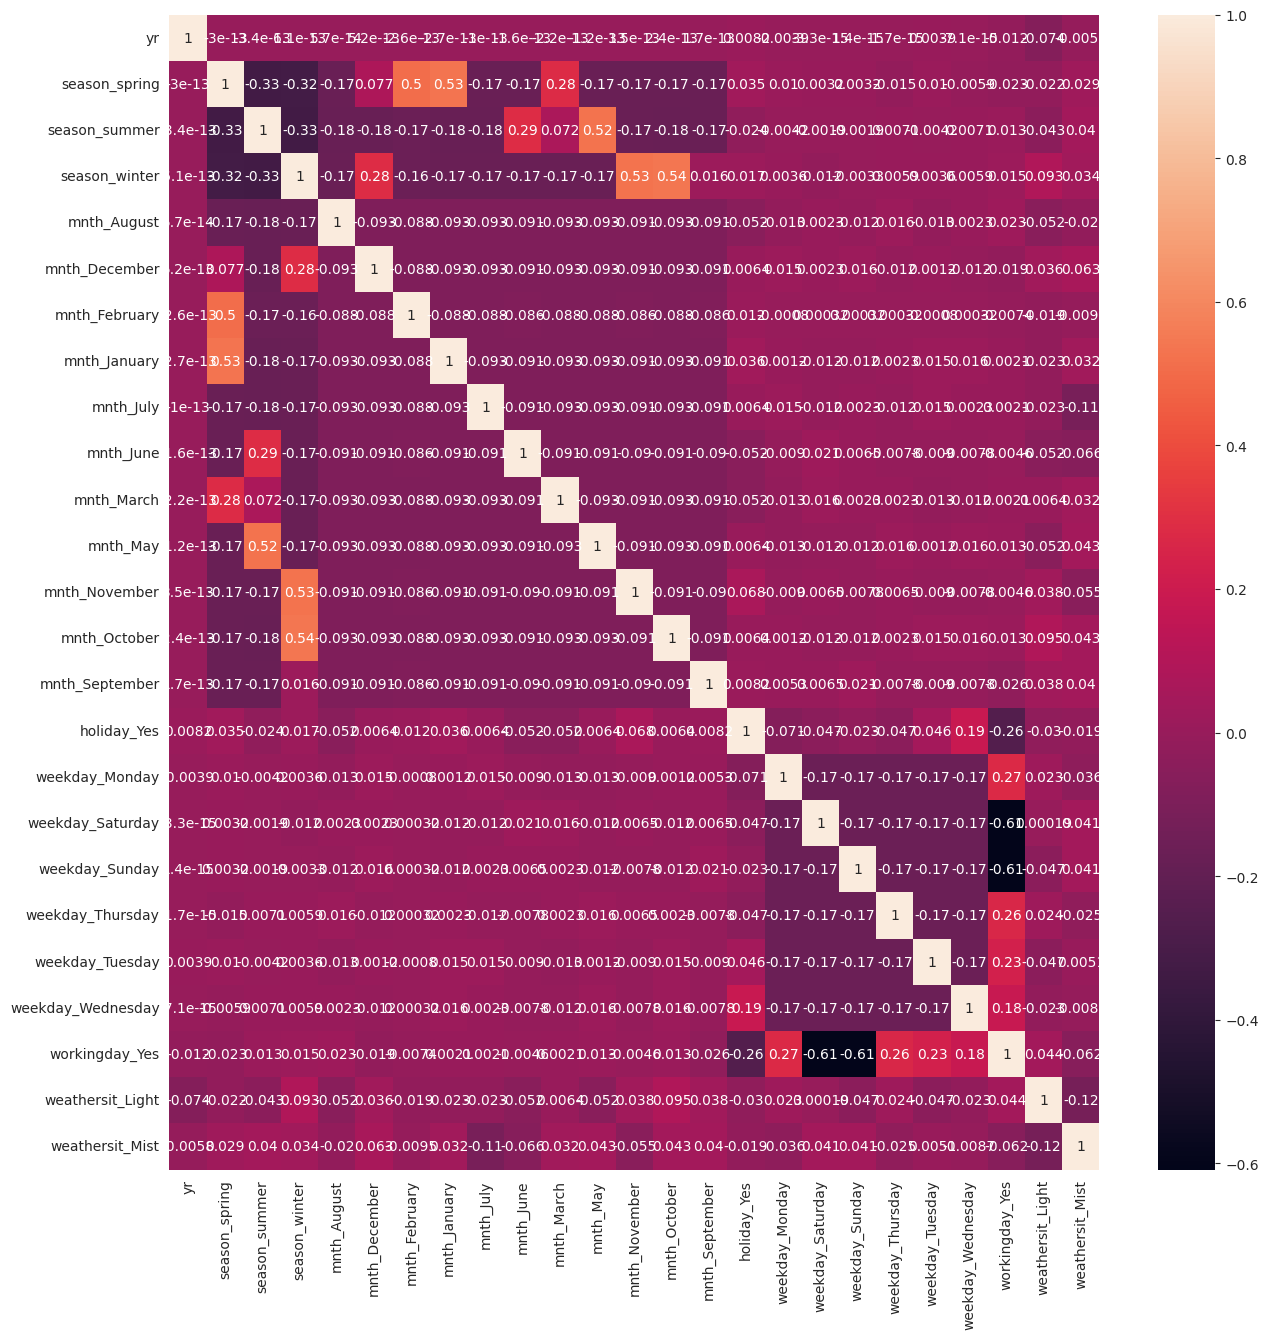

In [ ]:
plt.figure(figsize = [15, 15])
sns.heatmap(df.corr(), annot=True)

In [ ]:
bike_df['atemp'] = bike_df['atemp'].astype(int)
bike_df['hum'] = bike_df['hum'].astype(int)
bike_df['windspeed'] = bike_df['windspeed'].astype(int)

In [ ]:
bike_df.drop(bike_df.iloc[:,0:8], axis = 1, inplace = True)

In [ ]:
bike_df.head()

,atemp,hum,windspeed,cnt
0,18,80,10,985
1,17,69,16,801
2,9,43,16,1349
3,10,59,10,1562
4,11,43,12,1600


In [ ]:
bike_df = pd.concat([df, bike_df], axis = 1)

In [ ]:
bike_df

,yr,season_spring,season_summer,season_winter,mnth_August,mnth_December,mnth_February,mnth_January,mnth_July,mnth_June,...,weekday_Thursday,weekday_Tuesday,weekday_Wednesday,workingday_Yes,weathersit_Light,weathersit_Mist,atemp,hum,windspeed,cnt
0,2018,1,0,0,0,0,0,1,0,0,...,0,0,0,1,0,1,18,80,10,985
1,2018,1,0,0,0,0,0,1,0,0,...,0,1,0,1,0,1,17,69,16,801
2,2018,1,0,0,0,0,0,1,0,0,...,0,0,1,1,0,0,9,43,16,1349
3,2018,1,0,0,0,0,0,1,0,0,...,1,0,0,1,0,0,10,59,10,1562
4,2018,1,0,0,0,0,0,1,0,0,...,0,0,0,1,0,0,11,43,12,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,2019,1,0,0,0,1,0,0,0,0,...,0,0,0,1,0,1,11,65,23,2114
726,2019,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,12,59,10,3095
727,2019,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,12,75,8,1341
728,2019,1,0,0,0,1,0,0,0,0,...,0,0,0,1,0,0,11,48,23,1796


In [ ]:
bike_df.head()

,yr,season_spring,season_summer,season_winter,mnth_August,mnth_December,mnth_February,mnth_January,mnth_July,mnth_June,...,weekday_Thursday,weekday_Tuesday,weekday_Wednesday,workingday_Yes,weathersit_Light,weathersit_Mist,atemp,hum,windspeed,cnt
0,2018,1,0,0,0,0,0,1,0,0,...,0,0,0,1,0,1,18,80,10,985
1,2018,1,0,0,0,0,0,1,0,0,...,0,1,0,1,0,1,17,69,16,801
2,2018,1,0,0,0,0,0,1,0,0,...,0,0,1,1,0,0,9,43,16,1349
3,2018,1,0,0,0,0,0,1,0,0,...,1,0,0,1,0,0,10,59,10,1562
4,2018,1,0,0,0,0,0,1,0,0,...,0,0,0,1,0,0,11,43,12,1600


In [ ]:
bike_df['yr'].replace(to_replace = ['No', 'Yes'], value = [0, 1], inplace = True)

In [ ]:
bike_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   yr                 730 non-null    int32
 1   season_spring      730 non-null    int64
 2   season_summer      730 non-null    int64
 3   season_winter      730 non-null    int64
 4   mnth_August        730 non-null    int64
 5   mnth_December      730 non-null    int64
 6   mnth_February      730 non-null    int64
 7   mnth_January       730 non-null    int64
 8   mnth_July          730 non-null    int64
 9   mnth_June          730 non-null    int64
 10  mnth_March         730 non-null    int64
 11  mnth_May           730 non-null    int64
 12  mnth_November      730 non-null    int64
 13  mnth_October       730 non-null    int64
 14  mnth_September     730 non-null    int64
 15  holiday_Yes        730 non-null    int64
 16  weekday_Monday     730 non-null    int64
 17  weekday_Saturday

Divide the Dependent and Independent Values.

In [ ]:
# Trasnforming Dependent and independent values.
df_x = bike_df.iloc[:, : -1]
df_y = bike_df.iloc[:, -1]

        Splitting the train and test values to use the models

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(df_x, df_y, test_size = 0.2, random_state = 15)

    Creating Models

In [ ]:
regression = LinearRegression()
regression

LinearRegression()

In [ ]:
model =regression.fit(x_train, y_train)

In [ ]:
y_train_pred = regression.predict(x_train)

In [ ]:
print("Value of MAE : ", mean_absolute_error(y_train, y_train_pred))
print("Value of MSE : ", mean_squared_error(y_train, y_train_pred))
print("R2 Error: ", r2_score(y_train, y_train_pred))

Value of MAE :  545.9763564766395
Value of MSE :  547146.6547108613
R2 Error:  0.8483947760016523


In [ ]:
y_test_pred = regression.predict(x_test)

In [ ]:
print("Value of MAE : ", mean_absolute_error(y_test, y_test_pred))
print("Value of MSE : ", mean_squared_error(y_test, y_test_pred))
print("R2 Error: ", r2_score(y_test, y_test_pred))

Value of MAE :  614.9336819686123
Value of MSE :  721601.8102225353
R2 Error:  0.82984227958679


   The model's accuracy of 84% in training data and 82% in testing data indicates its suitability for application.



> The insights we gained here are:

1. Rental bike demand was strong in 2019 compared to 2018, with potential for
high demand in 2018 and 2020.
2. Because there is a clear season from June to September, more motorcycles are rented there.
3. Finally, there are more registered users than casual users, which may indicate an increase in business due to technology.

    --> The model's performance improves its accuracy, allowing it to anticipate values.
